In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

Saving archive.zip to archive.zip
Dataset loaded successfully!


In [4]:
# Display first five rows
print("First 5 rows:")
display(df.head())

# Display last five rows
print("Last 5 rows:")
display(df.tail())

# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("Column Names:")
print(df.columns.tolist())

# Information about dataset
df.info()

# Statistical summary
display(df.describe(include='all'))

First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Last 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


Dataset Shape: (891, 12)
Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Dooley, Mr. Patrick",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [5]:
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())

Numerical Columns:
['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

Categorical Columns:
['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


In [6]:
# Missing value count
print(df.isnull().sum())

# Missing value percentage
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_report = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': missing_percentage
})

display(missing_report)


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


,Missing Values,Percentage
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
Age,177,19.865320
SibSp,0,0.000000
Parch,0,0.000000
Ticket,0,0.000000
Fare,0,0.000000


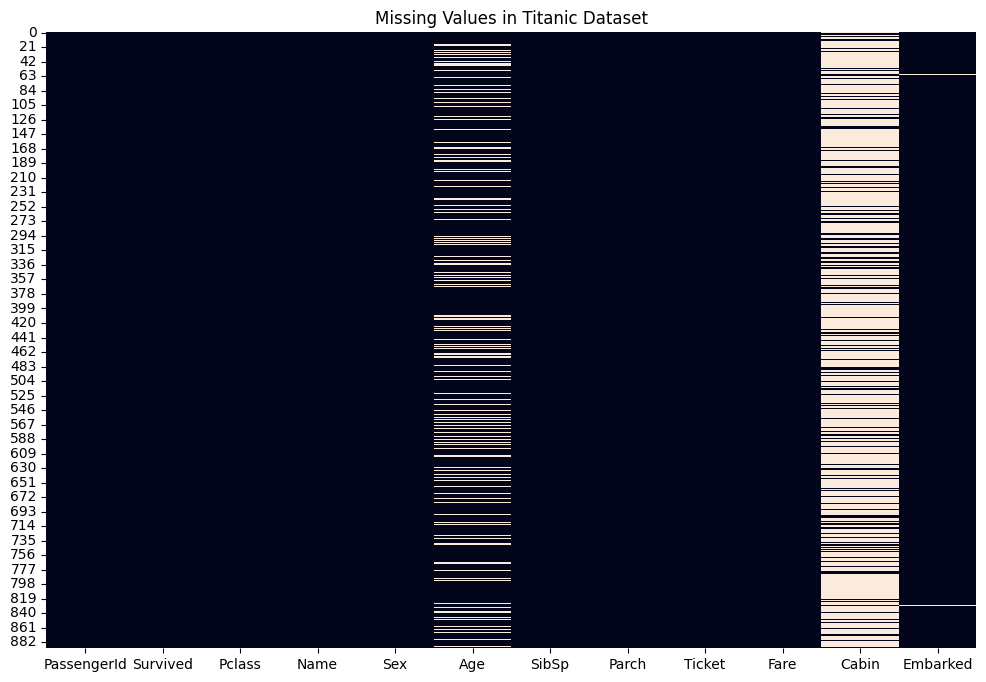

In [10]:
plt.figure(figsize=(12, 8))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values in Titanic Dataset")
plt.show()

In [13]:
# Create a copy of original dataset
cleaned_df = df.copy()

# Fill numerical missing values with median
if 'Age' in cleaned_df.columns:
    cleaned_df['Age'] = cleaned_df['Age'].fillna(
        cleaned_df['Age'].median()
    )

if 'Fare' in cleaned_df.columns:
    cleaned_df['Fare'] = cleaned_df['Fare'].fillna(
        cleaned_df['Fare'].median()
    )

# Fill categorical missing values with mode
if 'Embarked' in cleaned_df.columns:
    cleaned_df['Embarked'] = cleaned_df['Embarked'].fillna(
        cleaned_df['Embarked'].mode()[0]
    )

# Verify missing values
print(cleaned_df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64


In [14]:
# Count duplicate records
print("Duplicate Rows:",
      cleaned_df.duplicated().sum())

# Remove duplicate records
cleaned_df = cleaned_df.drop_duplicates()

# Remove extra spaces from categorical columns
for col in cleaned_df.select_dtypes(
    include='object'
).columns:
    cleaned_df[col] = cleaned_df[col].str.strip()

# Check dataset
print("Final Shape:", cleaned_df.shape)

Duplicate Rows: 0
Final Shape: (891, 12)


In [15]:
display(cleaned_df.describe())

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [16]:
if 'Sex' in cleaned_df.columns:
    print("Passenger count by gender:")
    print(cleaned_df['Sex'].value_counts())

Passenger count by gender:
Sex
male      577
female    314
Name: count, dtype: int64


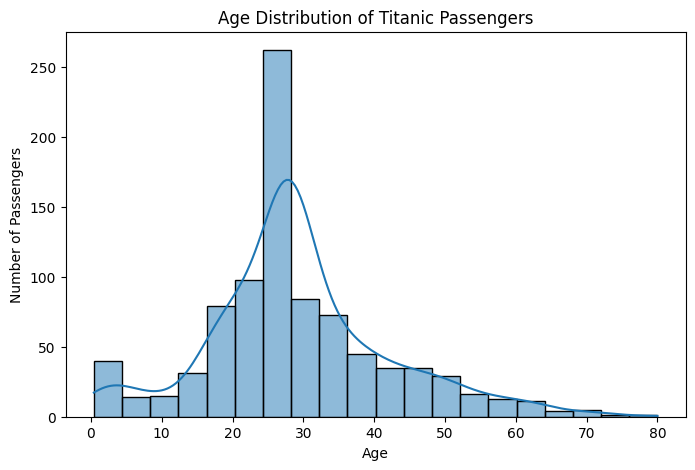

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(cleaned_df['Age'], bins=20, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

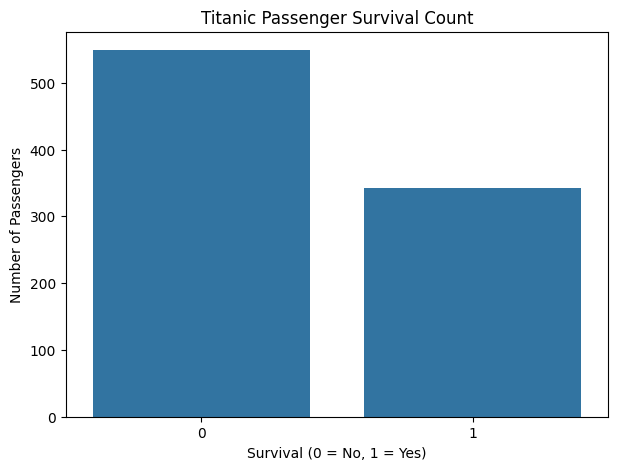

In [18]:
plt.figure(figsize=(7, 5))

sns.countplot(data=cleaned_df, x='Survived')

plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

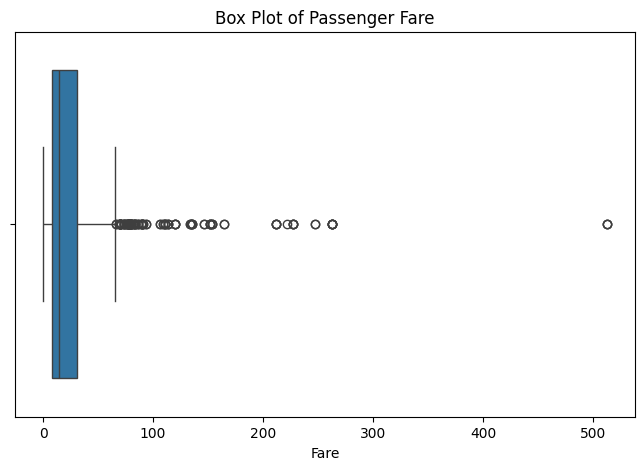

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=cleaned_df['Fare'])

plt.title("Box Plot of Passenger Fare")
plt.xlabel("Fare")

plt.show()

In [20]:
# Remove columns that are identifiers or unsuitable
# for basic machine learning analysis

columns_to_drop = [
    'PassengerId', 'Name', 'Ticket', 'Cabin'
]

cleaned_df = cleaned_df.drop(
    columns=columns_to_drop,
    errors='ignore'
)

# One-hot encoding
cleaned_df = pd.get_dummies(
    cleaned_df,
    columns=['Sex', 'Embarked'],
    drop_first=True,
    dtype=int
)

print("Dataset after encoding:")
display(cleaned_df.head())

print(cleaned_df.dtypes)


Dataset after encoding:


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1


Survived        int64
Pclass          int64
Age           float64
SibSp           int64
Parch           int64
Fare          float64
Sex_male        int64
Embarked_Q      int64
Embarked_S      int64
dtype: object


In [21]:
# Select numerical input features
scale_columns = [
    'Age', 'Fare', 'SibSp', 'Parch', 'Pclass'
]

scale_columns = [
    col for col in scale_columns
    if col in cleaned_df.columns
]

scaler = StandardScaler()

cleaned_df[scale_columns] = scaler.fit_transform(
    cleaned_df[scale_columns]
)

print("Dataset after scaling:")
display(cleaned_df.head())

Dataset after scaling:


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,0.827377,-0.565736,0.432793,-0.473674,-0.502445,1,0,1
1,1,-1.566107,0.663861,0.432793,-0.473674,0.786845,0,0,0
2,1,0.827377,-0.258337,-0.474545,-0.473674,-0.488854,0,0,1
3,1,-1.566107,0.433312,0.432793,-0.473674,0.420730,0,0,1
4,0,0.827377,0.433312,-0.474545,-0.473674,-0.486337,1,0,1


In [22]:
# Check final dataset shape
print("Final Dataset Shape:", cleaned_df.shape)

# Check missing values
print("\nMissing Values:")
print(cleaned_df.isnull().sum())

# Check duplicates
print("\nDuplicate Rows:",
      cleaned_df.duplicated().sum())

# Display final dataset
display(cleaned_df.head())

# Save prepared dataset
cleaned_df.to_csv(
    'Titanic_Prepared_Dataset.csv',
    index=False
)

print("Dataset saved successfully!")

Final Dataset Shape: (891, 9)

Missing Values:
Survived      0
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_male      0
Embarked_Q    0
Embarked_S    0
dtype: int64

Duplicate Rows: 116


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,0.827377,-0.565736,0.432793,-0.473674,-0.502445,1,0,1
1,1,-1.566107,0.663861,0.432793,-0.473674,0.786845,0,0,0
2,1,0.827377,-0.258337,-0.474545,-0.473674,-0.488854,0,0,1
3,1,-1.566107,0.433312,0.432793,-0.473674,0.420730,0,0,1
4,0,0.827377,0.433312,-0.474545,-0.473674,-0.486337,1,0,1


Dataset saved successfully!


In [23]:
files.download('Titanic_Prepared_Dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Conclusion:

The Titanic dataset was selected for data preparation and exploratory data analysis. The dataset was inspected to understand its structure, columns and data types. Missing values were identified and handled using median and mode imputation. Duplicate records and inconsistent categorical values were checked. EDA was performed using histograms, bar charts and box plots to understand passenger age, survival distribution and ticket fares. Categorical features were converted using one-hot encoding, and numerical features were standardized using StandardScaler. Finally, the prepared dataset was saved as a separate CSV file for future machine learning applications.